In [1]:
# features [1 sim, 0 nao]
# pelo longo?
# perna curta?
# faz auau?

porco1 = [0, 1, 0]
porco2 = [0, 1, 1]
porco3 = [1, 1, 0]

cachorro1 = [0, 1, 1]
cachorro2 = [1, 0, 1]
cachorro3 = [1, 1, 1]

# 1 -> porco, 0 -> cachorro
dados = [porco1, porco2, porco3, cachorro1, cachorro2, cachorro3]
classes = [1, 1, 1, 0, 0, 0]

In [2]:
dados

[[0, 1, 0], [0, 1, 1], [1, 1, 0], [0, 1, 1], [1, 0, 1], [1, 1, 1]]

In [3]:
from sklearn.svm import LinearSVC

model = LinearSVC()
model.fit(dados, classes)

,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo rand

In [4]:
animal_aleatorio = [1, 0, 1]
model.predict([animal_aleatorio])

array([0])

In [5]:
animal_aleatorio_2 = [0, 1, 0]
model.predict([animal_aleatorio_2])

array([1])

In [6]:
misterio1 = [1, 1, 1]
misterio2 = [1, 1, 0]
misterio3 = [0, 1, 1]

testes = [misterio1, misterio2, misterio3]
previsoes = model.predict(testes)

In [7]:
testes_classes = [0, 1, 0]

In [8]:
previsoes

array([0, 1, 0])

In [9]:
corretos = (previsoes == testes_classes).sum()

acuracia = (corretos / len(testes_classes)) * 100 

print(f"A acurácia foi de: {acuracia:.2f}%")

A acurácia foi de: 100.00%


In [10]:
from sklearn.metrics import accuracy_score

acuracia_sklearn = accuracy_score(testes_classes, previsoes) * 100
print(f"A acurácia foi de: {acuracia_sklearn:.2f}%")

A acurácia foi de: 100.00%


In [11]:
import pandas as pd 

df_tracking = pd.read_csv('./dados/tracking.csv')
df_tracking.head()

,inicial,palestras,contato,comprou,patrocinio
0,1,1,0,0,0
1,1,1,0,0,0
2,1,1,0,0,0
3,1,1,0,0,0
4,1,1,0,0,0


In [12]:
y = df_tracking["comprou"]
treino_y = y[:75]
treino_y.shape

(75,)

In [13]:
x = df_tracking[["inicial", "palestras", "contato", "patrocinio"]] 
# aqui precisamos de dois colchetes, pois um está criando o dataframe, e dentro o array com as colunas
treino_x = x[:75]

In [14]:
teste_x = x[75:]
teste_y = y[75:]
# os testes serão da linha 75 até o final

In [15]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score

modelo = LinearSVC()
modelo.fit(treino_x, treino_y) # treinamos aqui
previsoes = modelo.predict(teste_x) # testamos aqui 
previsoes

array([0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0,
       0, 0])

In [16]:
acuracia = accuracy_score(teste_y, previsoes) * 100
print(f"A acurácia foi de {acuracia:.2f}%")

A acurácia foi de 95.83%


In [17]:
from sklearn.model_selection import train_test_split

# train_test_split(x, y)
# aqui o x e o y são os dataframes que pegamos acima, y é y = df_tracking["comprou"] 
# x é x = df_tracking[["inicial", "palestras", "contato", "patrocinio"]] 

SEED = 469878

treino_x, teste_x, treino_y, teste_y = train_test_split(x, y, random_state=SEED, stratify=y)

print(f"Treinaremos com {len(treino_y)} elementos")
print(f"Testaremos com {len(teste_y)} elementos")

modelo = LinearSVC()
modelo.fit(treino_x, treino_y)
previsoes = modelo.predict(teste_x)

acuracia = accuracy_score(teste_y, previsoes) * 100
print(f"A acurácia foi de {acuracia:.2f}%")

Treinaremos com 74 elementos
Testaremos com 25 elementos
A acurácia foi de 96.00%


In [18]:
treino_y.value_counts()

comprou
0    49
1    25
Name: count, dtype: int64

In [19]:
teste_y.value_counts()

comprou
0    17
1     8
Name: count, dtype: int64

In [20]:
df_projetos = pd.read_csv('dados/projects.csv')
df_projetos.head()


,nao_finalizado,horas_esperadas,preco
0,0,75.0,6985.000000
1,1,0.0,4325.293458
2,0,87.0,14205.000000
3,1,13.0,100.000000
4,0,2.0,202.000000


In [21]:
df_projetos["finalizado"] = df_projetos["nao_finalizado"].map({1: 0, 0: 1})
df_projetos.head()

,nao_finalizado,horas_esperadas,preco,finalizado
0,0,75.0,6985.000000,1
1,1,0.0,4325.293458,0
2,0,87.0,14205.000000,1
3,1,13.0,100.000000,0
4,0,2.0,202.000000,1


<Axes: xlabel='horas_esperadas', ylabel='preco'>

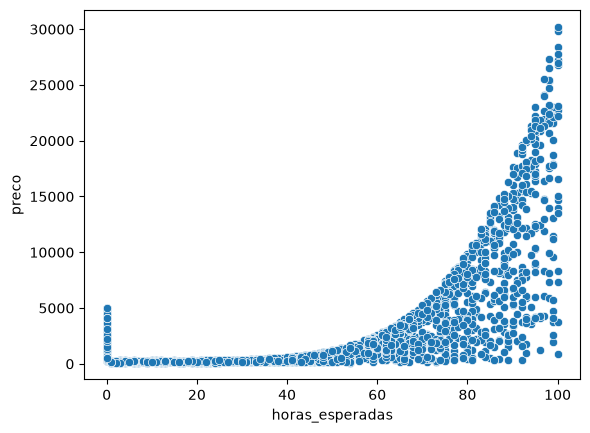

In [22]:
import seaborn as sns

sns.scatterplot(x="horas_esperadas", y="preco", data=df_projetos)

<Axes: xlabel='horas_esperadas', ylabel='preco'>

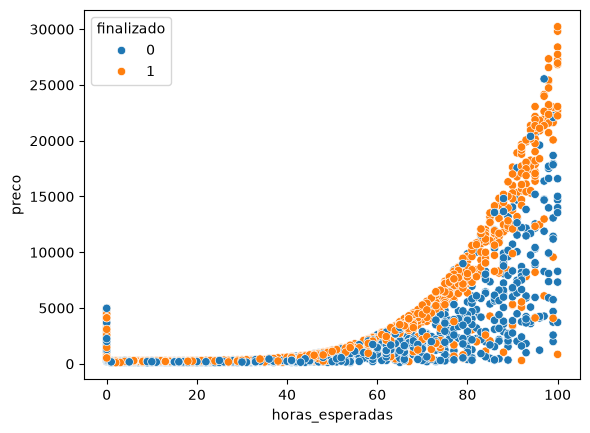

In [23]:
sns.scatterplot(x="horas_esperadas", y="preco", data=df_projetos, hue="finalizado")

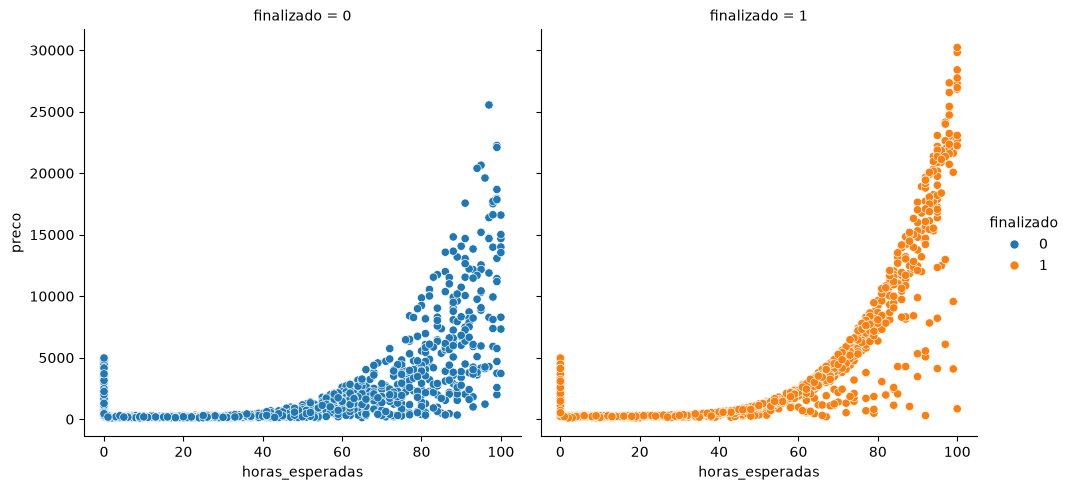

In [24]:
sns.relplot(x="horas_esperadas", y="preco", data=df_projetos, hue="finalizado", col="finalizado")

In [25]:
df_projetos = df_projetos.query("horas_esperadas > 0")
df_projetos.head()

,nao_finalizado,horas_esperadas,preco,finalizado
0,0,75.0,6985.0,1
2,0,87.0,14205.0,1
3,1,13.0,100.0,0
4,0,2.0,202.0,1
5,0,49.0,1096.0,1


In [26]:
x = df_projetos[["horas_esperadas", "preco"]]
y = df_projetos["finalizado"]

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score

SEED = 20

treino_x, teste_x, treino_y, teste_y = train_test_split(x, y, stratify = y)
print(f"Treinaremos com {len(treino_x)}")
print(f"Testaremos com {len(teste_x)}")

modelo = LinearSVC()
modelo.fit(treino_x, treino_y)
previsoes = modelo.predict(teste_x)

acuracia = accuracy_score(teste_y, previsoes) * 100
print(f"A acurácia foi de {acuracia:.2f}%")

Treinaremos com 1617
Testaremos com 540
A acurácia foi de 55.00%


In [28]:
previsoes_base = teste_y.sum() / len(teste_y) * 100 
# usamos o .sum pois o y é justamente a coluna finalizado, somando teremos todos os finalizados cujo valor é 1
print(f"A acurácia foi de {previsoes_base:.2f}%")

A acurácia foi de 52.59%


In [29]:
# Agora vamos plotar um gráfico para o teste e as previsões:  

In [30]:
x_min = teste_x["horas_esperadas"].min()
x_max = teste_x["horas_esperadas"].max()
y_min = teste_x["preco"].min()
y_max = teste_x["preco"].max()

print(f"x_min: {x_min}")
print(f"x_max: {x_max}")
print(f"y_min: {y_min}")
print(f"y_max: {y_max}")

x_min: 1.0
x_max: 100.0
y_min: 100.0
y_max: 30223.0


In [31]:
import numpy as np

pixels = 100

In [32]:
eixo_x = np.arange(x_min, x_max, (x_max - x_min) / pixels)
eixo_y = np.arange(y_min, y_max, (y_max - y_min) / pixels)
# (x_max - x_min) / pixels isso significa o step, ou seja o incremento entre cada ponto 

In [33]:
xx, yy = np.meshgrid(eixo_x, eixo_y)
pontos = np.c_[xx.ravel(), yy.ravel()]
pontos

array([[1.000000e+00, 1.000000e+02],
       [1.990000e+00, 1.000000e+02],
       [2.980000e+00, 1.000000e+02],
       ...,
       [9.703000e+01, 2.992177e+04],
       [9.802000e+01, 2.992177e+04],
       [9.901000e+01, 2.992177e+04]], shape=(10000, 2))

In [34]:
Z = modelo.predict(pontos) # só que isso trás tudo numa única sequência, então usamos o reshape para colocar em 100 x 100 pixels 
Z = Z.reshape(xx.shape)
Z


d:\Estudos\Machine Learning\Machine Learning - Classificação com SKLearn\projeto-sklearn\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearSVC was fitted with feature names
  warnings.warn(


array([[1, 1, 1, ..., 0, 0, 0],
       [1, 1, 1, ..., 0, 0, 0],
       [1, 1, 1, ..., 0, 0, 0],
       ...,
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1]], shape=(100, 100))

In [35]:
import matplotlib.pyplot as plt

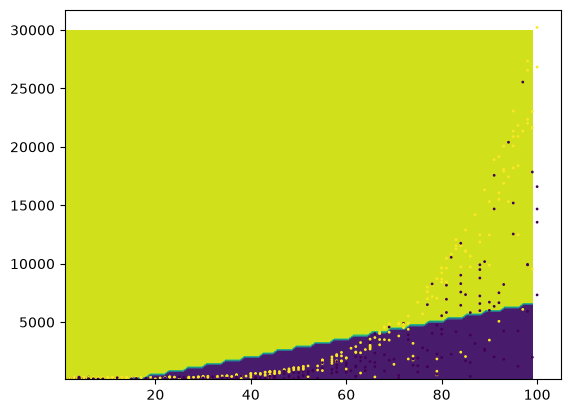

In [36]:
plt.contourf(xx, yy, Z)
plt.scatter(teste_x["horas_esperadas"], teste_x["preco"], c=teste_y, s=1)

In [39]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

SEED = 20

treino_x, teste_x, treino_y, teste_y = train_test_split(x, y,
                                                         random_state = SEED,
                                                         stratify = y)
print(f"Treinaremos com {len(treino_x)}")
print(f"Testaremos com {len(teste_x)}")

modelo = SVC(gamma='auto')
modelo.fit(treino_x, treino_y)
previsoes = modelo.predict(teste_x)

acuracia = accuracy_score(teste_y, previsoes) * 100
print(f"A acurácia foi de {acuracia:.2f}%")

Treinaremos com 1617
Testaremos com 540
A acurácia foi de 57.78%


d:\Estudos\Machine Learning\Machine Learning - Classificação com SKLearn\projeto-sklearn\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


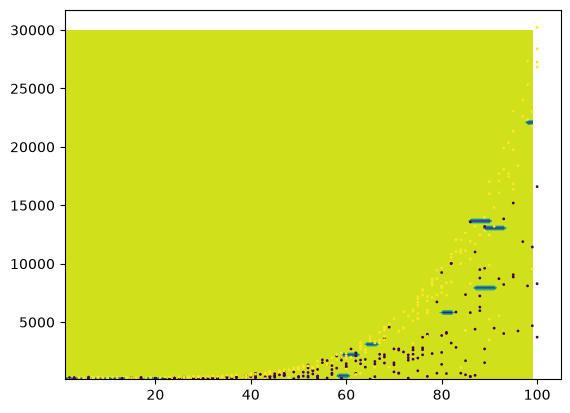

In [40]:
x_min = teste_x["horas_esperadas"].min()
x_max = teste_x["horas_esperadas"].max()
y_min = teste_x["preco"].min()
y_max = teste_x["preco"].max()

pixels = 100

eixo_x = np.arange(x_min, x_max, (x_max - x_min) / pixels)
eixo_y = np.arange(y_min, y_max, (y_max - y_min) / pixels)

xx, yy = np.meshgrid(eixo_x, eixo_y)
pontos = np.c_[xx.ravel(), yy.ravel()]

Z = modelo.predict(pontos)
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z)
plt.scatter(teste_x["horas_esperadas"], teste_x["preco"], c=teste_y, s=1)

In [41]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

SEED = 20

raw_treino_x, raw_teste_x, treino_y, teste_y = train_test_split(x, y,
                                                         random_state = SEED,
                                                         stratify = y)
print(f"Treinaremos com {len(raw_treino_x)}")
print(f"Testaremos com {len(raw_teste_x)}")

scaler = StandardScaler()
scaler.fit(raw_treino_x)

treino_x = scaler.transform(raw_treino_x)
teste_x = scaler.transform(raw_teste_x)

modelo = SVC(gamma='auto')
modelo.fit(treino_x, treino_y)
previsoes = modelo.predict(teste_x)

acuracia = accuracy_score(teste_y, previsoes) * 100
print(f"A acurácia foi de {acuracia:.2f}%")

Treinaremos com 1617
Testaremos com 540
A acurácia foi de 68.52%


In [42]:
teste_x

array([[ 1.21903398, -0.51627687],
       [ 0.868926  ,  0.53984011],
       [ 0.13369924, -0.4353314 ],
       ...,
       [ 1.74419595,  2.72476393],
       [ 0.23873164, -0.22249714],
       [-0.63653831, -0.53661392]], shape=(540, 2))

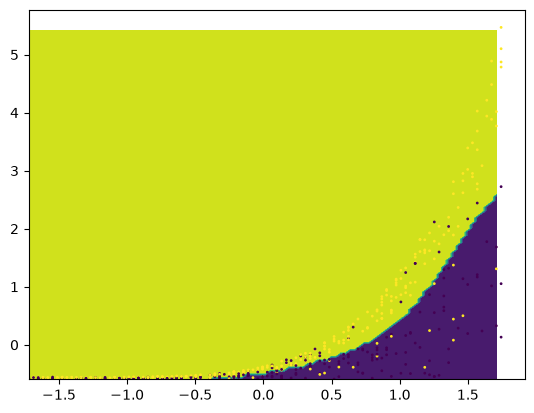

In [43]:
data_col1 = teste_x[:, 0]
data_col2 = teste_x[:, 1]

x_min = data_col1.min()
x_max = data_col1.max()
y_min = data_col2.min()
y_max = data_col2.max()

pixels = 100

eixo_x = np.arange(x_min, x_max, (x_max - x_min) / pixels)
eixo_y = np.arange(y_min, y_max, (y_max - y_min) / pixels)

xx, yy = np.meshgrid(eixo_x, eixo_y)
pontos = np.c_[xx.ravel(), yy.ravel()]

Z = modelo.predict(pontos)
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z)
plt.scatter(data_col1, data_col2, c=teste_y, s=1)